# 04 FMA MLP: four Keras architectures, a learning-rate check, and comparison with the best classical model

In [1]:
import sys; sys.path.append('..')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.preprocessing import LabelEncoder, StandardScaler
from src.config import FIGURES, SEED
from src.data import load_fma, fma_xy
from src.evaluate import evaluate, results_table, save_result

fma = load_fma()
X_train, y_train = fma_xy(fma, "training")
X_val, y_val = fma_xy(fma, "validation")
X_test, y_test = fma_xy(fma, "test")

# Scaler fitted on training only, then applied to validation and test.
scaler = StandardScaler().fit(X_train)
Xtr, Xva, Xte = (scaler.transform(X).astype("float32") for X in (X_train, X_val, X_test))
# LabelEncoder sorts genres alphabetically, the same order as le.classes_, so softmax column i is classes_[i].
le = LabelEncoder().fit(y_train)
ytr, yva = le.transform(y_train), le.transform(y_val)
Xtr.shape, list(le.classes_)

((6400, 518),
 ['Electronic',
  'Experimental',
  'Folk',
  'Hip-Hop',
  'Instrumental',
  'International',
  'Pop',
  'Rock'])

## 1. Four architectures

All use ReLU hidden layers, a softmax output, Adam, batch 64 and up to 200 epochs. EarlyStopping stops after 15 epochs without a lower validation loss and restores the best weights; ReduceLROnPlateau halves the learning rate after 5.

In [2]:
EPOCHS = 200
configs = {
    "256": dict(hidden=(256,)),
    "512-256": dict(hidden=(512, 256)),
    "512-256 dropout": dict(hidden=(512, 256), dropout=0.3),
    "512-256-128 dropout+L2": dict(hidden=(512, 256, 128), dropout=0.3, l2=1e-4),
}

def build(hidden, dropout=0.0, l2=0.0, lr=1e-3):
    tf.keras.utils.set_random_seed(SEED)  # same initial weights and shuffling for every run
    model = keras.Sequential([keras.Input((Xtr.shape[1],))])
    for units in hidden:
        # L2 adds l2 * sum(w^2) to the loss, pulling weights towards zero.
        model.add(keras.layers.Dense(units, activation="relu", kernel_regularizer=keras.regularizers.l2(l2)))
        if dropout:
            model.add(keras.layers.Dropout(dropout))  # zeroes 30% of units at random each training step
    model.add(keras.layers.Dense(len(le.classes_), activation="softmax"))
    model.compile(keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

def train(cfg, lr=1e-3, X=None, y=None):
    X, y = (Xtr, ytr) if X is None else (X, y)
    model = build(**cfg, lr=lr)
    hist = model.fit(X, y, validation_data=(Xva, yva), epochs=EPOCHS, batch_size=64, verbose=0,
                     callbacks=[keras.callbacks.EarlyStopping("val_loss", patience=15, restore_best_weights=True),
                                keras.callbacks.ReduceLROnPlateau("val_loss", factor=0.5, patience=5, min_lr=1e-6)])
    proba = model.predict(Xva, verbose=0)
    m, _ = evaluate(y_val, le.classes_[proba.argmax(1)], proba, labels=le.classes_)
    return {"model": model, "history": hist.history, "params": model.count_params(),
            "epochs": len(hist.history["loss"]), "best_val_loss": min(hist.history["val_loss"]),
            "val_macro_f1": m["macro_f1"], "val_accuracy": m["accuracy"],
            "val_precision": m["macro_precision"], "val_recall": m["macro_recall"], "val_fpr": m["macro_fpr"],
            "val_mcc": m["mcc"], "val_auc": m["macro_auc_ovr"]}

runs = {}
for name, cfg in configs.items():
    runs[name, 1e-3] = train(cfg)
    print(f"{name:24s} val macro-F1 {runs[name, 1e-3]['val_macro_f1']:.4f}  epochs {runs[name, 1e-3]['epochs']}")

256                      val macro-F1 0.5348  epochs 17
512-256                  val macro-F1 0.4944  epochs 16
512-256 dropout          val macro-F1 0.5342  epochs 17
512-256-128 dropout+L2   val macro-F1 0.5252  epochs 19


## 2. Learning-rate check on the best architecture

In [3]:
best_cfg = max(configs, key=lambda n: runs[n, 1e-3]["val_macro_f1"])
for lr in (1e-2, 1e-4):
    runs[best_cfg, lr] = train(configs[best_cfg], lr)
print("Best architecture:", best_cfg)

Best architecture: 256


## 3. Comparison table (validation only)

In [4]:
cols = ["params", "epochs", "best_val_loss", "val_accuracy", "val_precision", "val_recall",
        "val_fpr", "val_mcc", "val_auc", "val_macro_f1"]
table = pd.DataFrame({k: {c: r[c] for c in cols} for k, r in runs.items()}).T.rename_axis(["config", "lr"])
selected = table["val_macro_f1"].astype(float).idxmax()
print("Selected on validation macro-F1:", selected)
table.round(4)

Selected on validation macro-F1: ('256', np.float64(0.0001))


params  epochs  best_val_loss  val_accuracy  \
config                 lr                                                      
256                    0.0010  134920.0    17.0         1.4537        0.5350   
512-256                0.0010  399112.0    16.0         1.4333        0.5088   
512-256 dropout        0.0010  399112.0    17.0         1.3187        0.5425   
512-256-128 dropout+L2 0.0010  430984.0    19.0         1.4196        0.5288   
256                    0.0100  134920.0    16.0         1.6270        0.4888   
                       0.0001  134920.0    29.0         1.3555        0.5700   

                               val_precision  val_recall  val_fpr  val_mcc  \
config                 lr                                                    
256                    0.0010         0.5522      0.5350   0.0664   0.4710   
512-256                0.0010         0.5114      0.5088   0.0702   0.4427   
512-256 dropout        0.0010         0.5427      0.5425   0.0654   0.4796   
512-256-128 dropout+L2 0.0010         0.5375      0.5288   0.0673   0.4639   
256                    0.0100         0.5420      0.4887   0.0730   0.4194   
                       0.0001         0.5614      0.5700   0.0614   0.5092   

                               val_auc  val_macro_f1  
config                 lr                             
256                    0.0010   0.8547        0.5348  
512-256                0.0010   0.8550        0.4944  
512-256 dropout        0.0010   0.8657        0.5342  
512-256-128 dropout+L2 0.0010   0.8678        0.5252  
256                    0.0100   0.8484        0.5038  
                       0.0001   0.8622        0.5639

## 4. Loss curves: overfitting and its fix

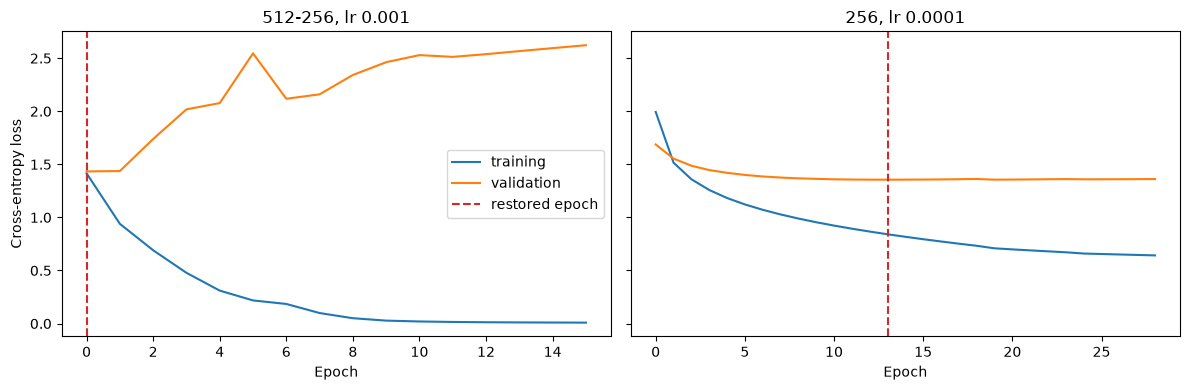

In [5]:
# The no-dropout (512, 256) run against the selected run (or the dropout run, if no-dropout was selected).
other = selected if selected != ("512-256", 1e-3) else ("512-256 dropout", 1e-3)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, key in zip(axes, [("512-256", 1e-3), other]):
    h = runs[key]["history"]
    ax.plot(h["loss"], label="training")
    ax.plot(h["val_loss"], label="validation")
    ax.axvline(int(np.argmin(h["val_loss"])), color="tab:red", ls="--", label="restored epoch")
    ax.set(title=f"{key[0]}, lr {key[1]:g}", xlabel="Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()
fig.tight_layout()
fig.savefig(FIGURES / "fma_mlp_loss_curves.png", dpi=200)

## 5. Test (once) and comparison with the best classical model (H2)

In [6]:
best = runs[selected]
proba = best["model"].predict(Xte, verbose=0)
metrics, per_class = evaluate(y_test, le.classes_[proba.argmax(1)], proba, labels=le.classes_)
cfg = configs[selected[0]]
save_result("mlp", "fma", metrics, params={"hidden": list(cfg["hidden"]), "dropout": cfg.get("dropout", 0.0),
            "l2": cfg.get("l2", 0.0), "lr": selected[1], "epochs": best["epochs"], "n_params": best["params"]})
results_table("fma")[["accuracy", "macro_f1", "mcc", "macro_auc_ovr"]]

,accuracy,macro_f1,mcc,macro_auc_ovr
model,,,,
random_forest,0.4900,0.4867,0.4175,0.8280
mlp,0.4675,0.4655,0.3916,0.8107
logistic_regression,0.4512,0.4494,0.3731,0.8131
decision_tree,0.3625,0.3598,0.2719,0.7398
naive_bayes,0.3713,0.3494,0.2866,0.7810
knn,0.2975,0.2938,0.1988,0.6660
zeror,0.1250,0.0278,0.0000,0.5000


In [7]:
per_class.sort_values("recall_tpr")

,precision,recall_tpr,fpr,f1,support
Folk,0.2093,0.18,0.0971,0.1935,100
Experimental,0.3878,0.38,0.0857,0.3838,100
Pop,0.3220,0.38,0.1143,0.3486,100
Instrumental,0.4536,0.44,0.0757,0.4467,100
International,0.5484,0.51,0.0600,0.5285,100
Electronic,0.5600,0.56,0.0629,0.5600,100
Rock,0.5644,0.57,0.0629,0.5672,100
Hip-Hop,0.6729,0.72,0.0500,0.6957,100


H2 predicts the MLP gives at most a small gain over the best classical model. Compare the `mlp` row with the best other row above.

## 6. Overfitting experiment: Classifiers 1, 2 and 3

The selected configuration is retrained after moving 0%, 30% and 60% of the training split into the test split (stratified by genre). Less training data should lower test accuracy and widen the train-test gap. Validation is unchanged and still drives early stopping. This is a diagnostic, so these runs are not saved as results.

FMA's split keeps each artist in one split, but the moved tracks share artists with the tracks left in training, so accuracy on the moved part is optimistic. `orig_test_acc` scores the original 800 test tracks only, which is the fair comparison across the three classifiers.

,train_size,test_size,epochs,train_acc,test_acc,orig_test_acc,gap
classifier,,,,,,,
Classifier 1,6400,800,29,0.7466,0.4675,0.4675,0.2791
Classifier 2,4480,2720,30,0.7525,0.5401,0.4538,0.2987
Classifier 3,2560,4640,32,0.7562,0.5254,0.4325,0.3238


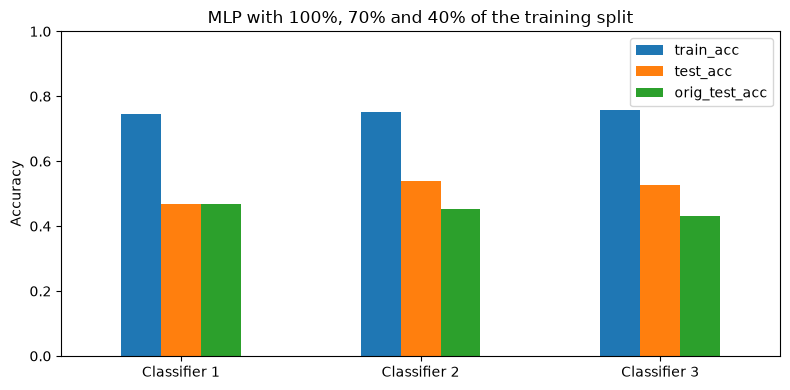

In [8]:
from sklearn.model_selection import train_test_split
yte = le.transform(y_test)
rows = []
for i, frac in enumerate([0.0, 0.3, 0.6], 1):
    if frac:
        Xfit, Xmove, yfit, ymove = train_test_split(Xtr, ytr, test_size=frac, stratify=ytr, random_state=SEED)
        r = train(configs[selected[0]], selected[1], Xfit, yfit)
        Xeval, yeval = np.vstack([Xte, Xmove]), np.concatenate([yte, ymove])
    else:
        Xfit, yfit, Xeval, yeval, r = Xtr, ytr, Xte, yte, best  # Classifier 1 is the selected model itself
    acc = lambda X, y: float((r["model"].predict(X, verbose=0).argmax(1) == y).mean())
    rows.append({"classifier": f"Classifier {i}", "train_size": len(yfit), "test_size": len(yeval),
                 "epochs": r["epochs"], "train_acc": acc(Xfit, yfit), "test_acc": acc(Xeval, yeval),
                 "orig_test_acc": acc(Xte, yte)})
over = pd.DataFrame(rows).set_index("classifier")
over["gap"] = over["train_acc"] - over["orig_test_acc"]

ax = over[["train_acc", "test_acc", "orig_test_acc"]].plot.bar(rot=0, figsize=(8, 4))
ax.set(ylabel="Accuracy", xlabel="", ylim=(0, 1),
       title="MLP with 100%, 70% and 40% of the training split")
ax.figure.tight_layout()
ax.figure.savefig(FIGURES / "fma_mlp_overfitting.png", dpi=200)
over.round(4)

## 7. Is the gap to the random forest real?

The random forest is refitted with its saved settings from notebook 03. Both models' test predictions are resampled together 1,000 times (paired bootstrap over the 800 test tracks) to get a 95% interval for each macro-F1 and for their difference. If the interval for the difference contains 0, the test set cannot separate the two models.

In [10]:
import json
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score
from sklearn.pipeline import Pipeline
from src.config import RESULTS

rf_params = json.loads((RESULTS / "fma" / "random_forest.json").read_text())["params"]
# Same pipeline, settings and seed as notebook 03, so the test predictions match its saved result.
rf = Pipeline([("scale", StandardScaler()), ("model", RandomForestClassifier(**rf_params, random_state=SEED))]).fit(X_train, y_train)
yt = y_test.to_numpy()
pred = {"mlp": le.classes_[proba.argmax(1)], "random_forest": rf.predict(X_test)}

rng = np.random.default_rng(SEED)
boot = []
for _ in range(1000):
    i = rng.integers(0, len(yt), len(yt))  # same resampled tracks for both models
    boot.append([f1_score(yt[i], p[i], average="macro") for p in pred.values()])
boot = np.array(boot)
diff = boot[:, 0] - boot[:, 1]
print(f"MLP minus RF macro-F1: {f1_score(yt, pred['mlp'], average='macro') - f1_score(yt, pred['random_forest'], average='macro'):+.3f}, "
      f"95% interval [{np.percentile(diff, 2.5):+.3f}, {np.percentile(diff, 97.5):+.3f}]")
pd.DataFrame({"macro_f1": [f1_score(yt, p, average="macro") for p in pred.values()],
              "ci_low": np.percentile(boot, 2.5, axis=0), "ci_high": np.percentile(boot, 97.5, axis=0)},
             index=list(pred)).round(3)

MLP minus RF macro-F1: -0.021, 95% interval [-0.055, +0.012]


,macro_f1,ci_low,ci_high
mlp,0.466,0.430,0.498
random_forest,0.487,0.453,0.517


## Findings

- **Network size:** a single layer of 256 units did best (validation macro-F1 0.535). Bigger networks did not help: 512-256 scored 0.494.
- **Dropout:** adding dropout to the 512-256 network raised it from 0.494 to 0.534, so the bigger network was overfitting.
- **Learning rate:** 1e-4 was best (0.564), against 0.535 at 1e-3 and 0.504 at 1e-2. It took longer to train (29 epochs vs 17). The final MLP is 256 units at learning rate 1e-4.
- **Loss curves:** without dropout, the 512-256 network overfits from the first epoch; its validation loss rises from 1.4 to 2.6. The final network's validation loss stays flat at about 1.35.
- **Test result:** the MLP scored 0.466 macro-F1 and got 374 of 800 tracks right. The random forest scored 0.487 with 392 right. It beat every model except the random forest, including logistic regression (0.449).
- **Is the gap real?** No. The bootstrap puts the MLP 0.021 below the random forest, with a 95% interval of -0.055 to +0.012. The interval includes 0, so neither model is clearly better.
- **H2:** supported. The neural network gave no gain over the best classical model on these features.
- **Hardest genres:** Folk (recall 0.18), Experimental (0.38) and Pop (0.38), the same three as for the random forest. Hip-Hop is easiest (0.72).
- **Less training data:** with 6,400, 4,480 and 2,560 training tracks, test accuracy falls from 0.468 to 0.454 to 0.433, and the train-test gap grows from 0.28 to 0.30 to 0.32.
- **Reproducibility:** TensorFlow on CPU gives slightly different results each run, even with a fixed seed. An earlier run scored 0.463, so the variation is much smaller than the gap to the random forest.
